In [1]:
from google.colab import files

uploaded = files.upload()


Saving OnlineRetail.csv to OnlineRetail.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE


In [3]:
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name, encoding="latin1")

print(df.head())
print("Shape:", df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
Shape: (541909, 8)


In [4]:
print(df.info())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268


In [5]:
df = df.dropna(subset=["CustomerID"])

print("Rows after removing missing CustomerID:", len(df))

Rows after removing missing CustomerID: 406829


In [6]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

print("Rows after cleaning:", len(df))

Rows after cleaning: 397884


In [7]:
df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 392692


In [8]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print(df[["Quantity", "UnitPrice", "TotalAmount"]].head())

   Quantity  UnitPrice  TotalAmount
0         6       2.55        15.30
1         6       3.39        20.34
2         8       2.75        22.00
3         6       3.39        20.34
4         6       3.39        20.34


In [9]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(df["InvoiceDate"].head())

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]


In [10]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [11]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [12]:
print(rfm.describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [13]:
rfm_log = np.log1p(rfm)

print(rfm_log.head())

             Recency  Frequency   Monetary
CustomerID                                
12346.0     5.789960   0.693147  11.253955
12347.0     1.098612   2.079442   8.368925
12348.0     4.330733   1.609438   7.494564
12349.0     2.995732   0.693147   7.472245
12350.0     5.739793   0.693147   5.815324


In [14]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print(rfm_scaled[:5])

[[ 1.46199281 -0.95521426  3.7077163 ]
 [-2.03873442  1.07442519  1.41490344]
 [ 0.37310424  0.38630445  0.72002428]
 [-0.62308592 -0.95521426  0.70228691]
 [ 1.42455753 -0.95521426 -0.61451388]]


In [15]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"],
    index=rfm.index
)

print(pca_df.head())

                 PC1       PC2
CustomerID                    
12346.0     0.873338  2.691611
12347.0     2.551874 -0.802858
12348.0     0.477339  0.747867
12349.0     0.147609 -0.457066
12350.0    -1.686255  0.679035


In [16]:
print("PC1 variance:", pca.explained_variance_ratio_[0])
print("PC2 variance:", pca.explained_variance_ratio_[1])

PC1 variance: 0.7507863350737912
PC2 variance: 0.18786648312516213


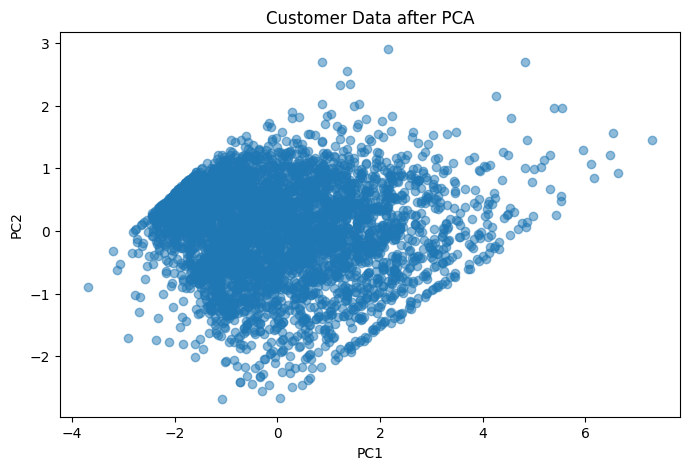

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customer Data after PCA")

plt.show()

In [18]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm.head())

            Recency  Frequency  Monetary  KMeans_Cluster
CustomerID                                              
12346.0         326          1  77183.60               3
12347.0           2          7   4310.00               0
12348.0          75          4   1797.24               3
12349.0          19          1   1757.55               2
12350.0         310          1    334.40               1


In [19]:
print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


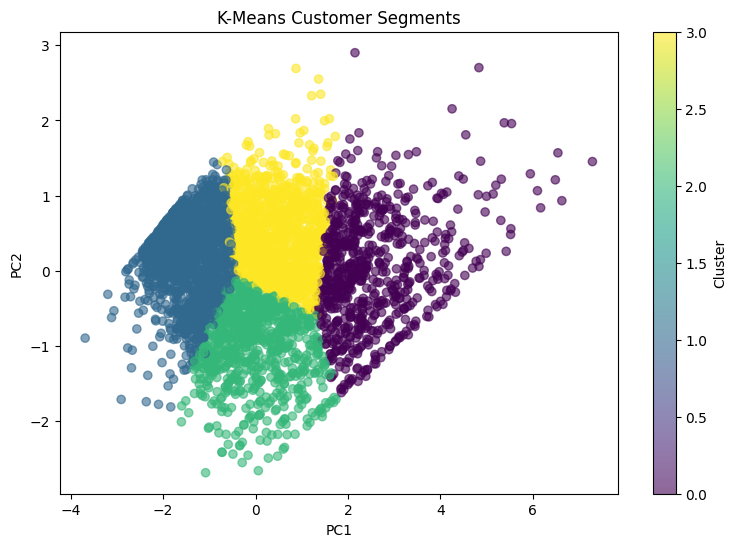

In [20]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Customer Segments")

plt.colorbar(label="Cluster")

plt.show()

In [21]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=8
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(rfm_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1      71
 0    2784
 1    1483
Name: count, dtype: int64


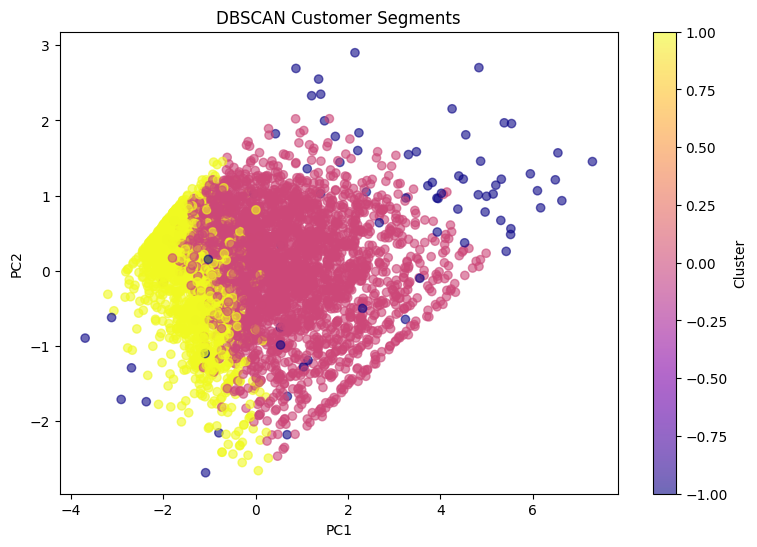

In [22]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=rfm["DBSCAN_Cluster"],
    cmap="plasma",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN Customer Segments")

plt.colorbar(label="Cluster")

plt.show()

In [23]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

tsne_data = tsne.fit_transform(rfm_scaled)

tsne_df = pd.DataFrame(
    tsne_data,
    columns=["TSNE1", "TSNE2"],
    index=rfm.index
)

print(tsne_df.head())

                TSNE1      TSNE2
CustomerID                      
12346.0     33.738564  35.464371
12347.0     39.335251 -31.393911
12348.0     39.893288  28.111427
12349.0    -11.341532 -25.516500
12350.0    -66.284767  10.236936


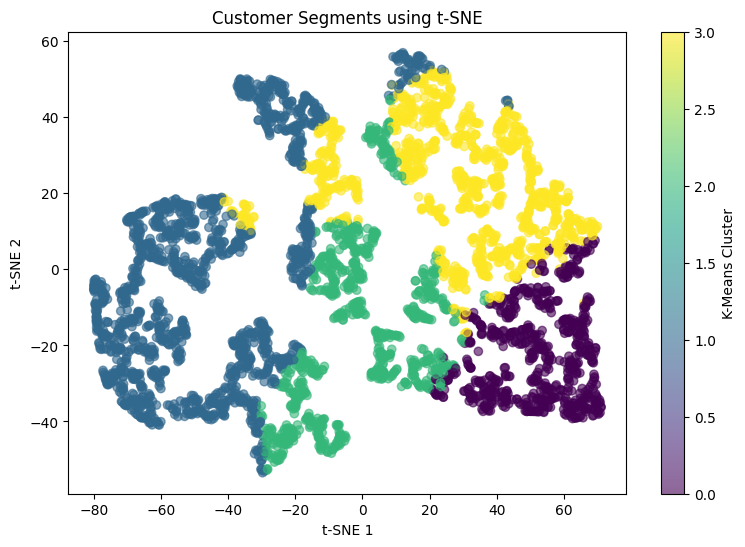

In [24]:
plt.figure(figsize=(9, 6))

plt.scatter(
    tsne_df["TSNE1"],
    tsne_df["TSNE2"],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segments using t-SNE")

plt.colorbar(label="K-Means Cluster")

plt.show()

In [25]:
cluster_summary = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

print(cluster_summary.round(2))

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 12.17      13.75   8088.02
1                181.51       1.32    341.00
2                 17.70       2.19    557.32
3                 71.64       4.08   1801.78


In [26]:
cluster_size = rfm["KMeans_Cluster"].value_counts().sort_index()

print(cluster_size)

KMeans_Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [27]:
persona_names = {
    0: "Champions",
    1: "Loyal Customers",
    2: "Potential Customers",
    3: "At-Risk Customers"
}

rfm["Persona"] = rfm["KMeans_Cluster"].map(persona_names)

print(
    rfm[
        [
            "Recency",
            "Frequency",
            "Monetary",
            "KMeans_Cluster",
            "Persona"
        ]
    ].head()
)

            Recency  Frequency  Monetary  KMeans_Cluster              Persona
CustomerID                                                                   
12346.0         326          1  77183.60               3    At-Risk Customers
12347.0           2          7   4310.00               0            Champions
12348.0          75          4   1797.24               3    At-Risk Customers
12349.0          19          1   1757.55               2  Potential Customers
12350.0         310          1    334.40               1      Loyal Customers


In [28]:
persona_summary = rfm.groupby("Persona").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Persona": "count"
})

persona_summary = persona_summary.rename(
    columns={"Persona": "Number of Customers"}
)

print(persona_summary.round(2))

                     Recency  Frequency  Monetary  Number of Customers
Persona                                                               
At-Risk Customers      71.64       4.08   1801.78                 1166
Champions              12.17      13.75   8088.02                  713
Loyal Customers       181.51       1.32    341.00                 1622
Potential Customers    17.70       2.19    557.32                  837


In [29]:
rfm.to_csv("customer_segments.csv")

print("Customer segmentation saved successfully.")

Customer segmentation saved successfully.
